# Lab 08: Graphs, latent variables, and what the survey didn't keep

**ASTR 457, Fall 2026, posted Thu Oct 29, due Wed Nov 4 by noon (fork → PR, as always)**

This week we wrote graphs as `PyMC` code, and put a detector into the likelihood. You're going to do both, on your own midterm supernovae, on a survey that rejects everything below a threshold, and on one real Type Ia supernova observed in six bands.

Put your notebook in `submissions/<your netid>/lab08.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 35%, Part 2 30%, Part 3 25%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
import pymc as pm
import pytensor.tensor as pt
import arviz as az

NETID = 'nraja3'   # <-- set this
LAB = '../../labs/08/data/'                              # from submissions/<your netid>/
MIDTERM = f'../../labs/midterm/data/{NETID}/'

C:\Users\nicco\miniforge3\envs\astr457\Lib\site-packages\arviz\__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


## Part 1: Your midterm, as a graph (35%)

On the midterm you fit the Tripp relation to your 250 supernovae (`p2_pantheon_sne.csv` in your midterm data folder):

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10).$$

In the posted solution's 2e simulation, the 68% interval on $\beta$ contained the true $\beta$ in only **6%** of 200 fake datasets! The other four parameters covered the truth 62-66% of the time. The solution blamed attenuation. You're going to draw the graph that shows where it comes from, build the model that removes it, and check that it does.

1. Draw the probabilistic graphical model of your midterm fit (your 2b likelihood), using the same key as Day 18 - parameters you fit as blue circles, latent (unobserved) values as white circles, data as grey circles, fixed quantities as dots, and a plate over supernovae. Draw it by hand (a photo is fine) or with any drawing tool, and put the image in your notebook. Then draw the graph of how the data were actually made. Each supernova has a *true* stretch $x_{1,i}$ and a *true* color $c_i$, drawn from a population (a mean and a width for each), and the catalog's $\hat m_{B,i}$, $\hat x_{1,i}$, $\hat c_i$ are noisy measurements of the true values, with that supernova's $3\times3$ covariance $C_i$. Which arrows does the midterm's graph lack, and which circle did it shade grey that should be white?
2. Fit the second graph in `PyMC`, with latent `x1_true` and `c_true` (one per supernova, `shape=N`), a mean and a width for each population, and the three observed quantities together in a `pm.MvNormal` with each $C_i$. Add $\sigma_{\rm int}^2$ and the peculiar-velocity variance to the $m_B$ term only. Handle the contaminants as you did on the midterm, and explain how. Pick centered or non-centered by Day 19's rule (compare the measurement errors with the population widths), and justify your choice. Report the largest $\hat R$, the smallest bulk effective sample size (the latent values included) and the number of divergences, then $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 68% intervals, in a table next to your midterm values.
3. Rerun the solution's 2e simulation at your own stretches, colors and covariances, with at least 20 fake datasets and true $\beta = 2.9$ (the other true values are in the solution, which uses your catalog $x_1$ and $c$ as the true ones). Fit each with your midterm model and with the latent model, and report the mean $\hat\beta$ for each model with its standard error (the scatter over datasets divided by $\sqrt{N_{\rm sim}}$). Then explain, in a few sentences, why using the measured $x_1$ and $c$ as the regressors, with their errors only in the variance (as the midterm did), biases $\beta$ toward zero, why the latent model doesn't, and why $\beta$ is biased more than $\alpha$. Think particularly about $c$'s errors compared with the spread of $c$, and $x_1$'s errors compared with the spread of $x_1$.

#### Hints:
- You don't need to sample each fake dataset in 1.3. Everything here is Gaussian, so you can integrate the true $x_1$ and $c$ out on paper - each supernova's observed $(\hat m_B, \hat x_1, \hat c)$ is then Gaussian, with a mean and covariance that depend only on the parameters and the two populations. Write them down, maximize that likelihood, and check its answer on your real data against your `PyMC` fit.
- **Don't use `pm.find_MAP` on the 1.2 model.** Its peak over all the latent values at once is degenerate (the population width collapses), and you'll get a wrong $\beta$ that looks reasonable.

DATA SHAPE:
(250, 13)

COLUMN NAMES:
['name', 'z', 'mB', 'mB_err', 'x1', 'x1_err', 'c', 'c_err', 'cov_mB_x1', 'cov_mB_c', 'cov_x1_c', 'host_logmass', 'host_logmass_err']

FIRST FIVE ROWS:
     name        z       mB    mB_err        x1    x1_err         c     c_err  cov_mB_x1  cov_mB_c  cov_x1_c  host_logmass  host_logmass_err
0  000014  0.13614  19.3954  0.044841  0.475770  0.578820 -0.111842  0.033921   0.002586  0.000890  0.001044       9.80415             0.048
1  100405  0.10294  19.1817  0.084243 -0.941741  0.364480  0.044595  0.054733   0.027148  0.004400  0.015542      10.32040             0.100
2    1032  0.12921  20.1088  0.056393 -2.539300  0.204280  0.052555  0.038995   0.002949  0.001605  0.001017      10.27770             0.067
3  120225  0.10713  19.4712  0.051837 -0.829043  0.888220 -0.070405  0.065643   0.006763  0.000891 -0.051723      11.41830             0.100
4    1241  0.08870  18.8841  0.042819 -0.551806  0.078987  0.055246  0.024000   0.000582  0.000779  0.00005

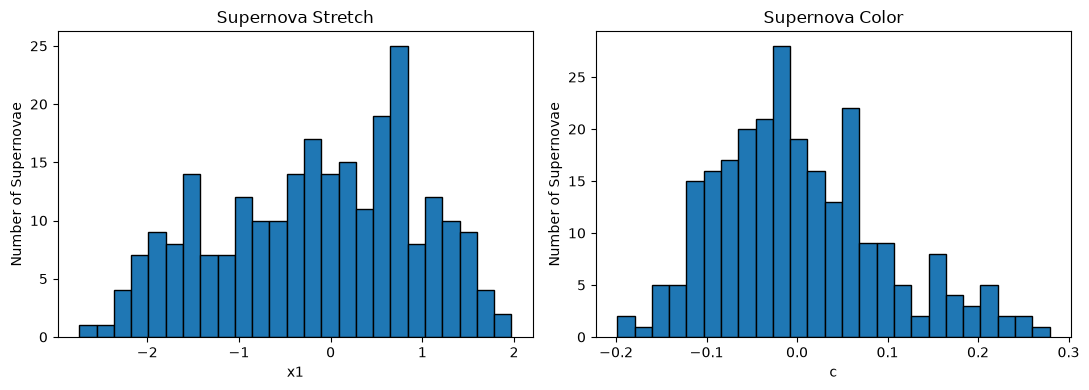

In [5]:
# Part 1: your work here

sn = pd.read_csv(MIDTERM + 'p2_pantheon_sne.csv')

print("DATA SHAPE:")
print(sn.shape)

print("\nCOLUMN NAMES:")
print(sn.columns.tolist())

print("\nFIRST FIVE ROWS:")
print(sn.head().to_string())

print("\nSUMMARY STATISTICS:")
print(sn.describe().to_string())

print("\nMISSING VALUES:")
print(sn.isna().sum().to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(sn['x1'].dropna(), bins=25, edgecolor='black')
axes[0].set_title('Supernova Stretch')
axes[0].set_xlabel('x1')
axes[0].set_ylabel('Number of Supernovae')

axes[1].hist(sn['c'].dropna(), bins=25, edgecolor='black')
axes[1].set_title('Supernova Color')
axes[1].set_xlabel('c')
axes[1].set_ylabel('Number of Supernovae')

plt.tight_layout()
plt.show()

In [6]:
print("AVAILABLE COLUMNS:")
for col in sn.columns:
    print(col)

print("\nPOSSIBLE UNCERTAINTY/COVARIANCE COLUMNS:")
for col in sn.columns:
    if any(s in col.lower() for s in ['err', 'sigma', 'cov', 'var']):
        print(col)

print("\nSTRETCH AND COLOR STATISTICS:")
for col in ['x1', 'c']:
    if col in sn.columns:
        print(f"{col}:")
        print("  Mean:", sn[col].mean())
        print("  Standard deviation:", sn[col].std())
        print("  Minimum:", sn[col].min())
        print("  Maximum:", sn[col].max())

AVAILABLE COLUMNS:
name
z
mB
mB_err
x1
x1_err
c
c_err
cov_mB_x1
cov_mB_c
cov_x1_c
host_logmass
host_logmass_err

POSSIBLE UNCERTAINTY/COVARIANCE COLUMNS:
mB_err
x1_err
c_err
cov_mB_x1
cov_mB_c
cov_x1_c
host_logmass_err

STRETCH AND COLOR STATISTICS:
x1:
  Mean: -0.146982664
  Standard deviation: 1.084035738181113
  Minimum: -2.74165
  Maximum: 1.97167
c:
  Mean: 0.0025278159999999987
  Standard deviation: 0.09258092377726608
  Minimum: -0.198625
  Maximum: 0.27902


In [7]:
print("NUMBER OF SUPERNOVAE:", len(sn))

print("\nFIRST 10 SUPERNOVAE:")
print(sn.head(10).to_string())

print("\nNUMERIC COLUMNS:")
print(sn.select_dtypes(include=[np.number]).columns.tolist())

print("\nCORRELATIONS:")
print(sn.select_dtypes(include=[np.number]).corr().round(3).to_string())

NUMBER OF SUPERNOVAE: 250

FIRST 10 SUPERNOVAE:
      name        z       mB    mB_err        x1    x1_err         c     c_err  cov_mB_x1  cov_mB_c  cov_x1_c  host_logmass  host_logmass_err
0   000014  0.13614  19.3954  0.044841  0.475770  0.578820 -0.111842  0.033921   0.002586  0.000890  0.001044       9.80415             0.048
1   100405  0.10294  19.1817  0.084243 -0.941741  0.364480  0.044595  0.054733   0.027148  0.004400  0.015542      10.32040             0.100
2     1032  0.12921  20.1088  0.056393 -2.539300  0.204280  0.052555  0.038995   0.002949  0.001605  0.001017      10.27770             0.067
3   120225  0.10713  19.4712  0.051837 -0.829043  0.888220 -0.070405  0.065643   0.006763  0.000891 -0.051723      11.41830             0.100
4     1241  0.08870  18.8841  0.042819 -0.551806  0.078987  0.055246  0.024000   0.000582  0.000779  0.000050       9.91509             0.103
5  1255502  0.14834  19.3979  0.072830  1.051480  0.289100 -0.089005  0.045225   0.016928  0.002958 

**ANSWER (the two graphs, the table, the simulation result, then the explanation):**

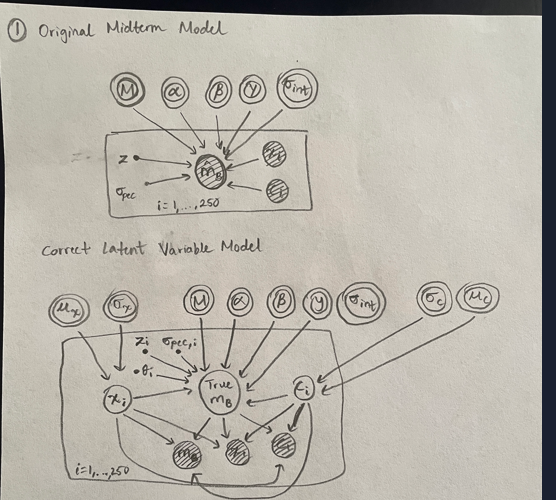

My midterm model was missing the true stretch and color values and their population connections. I treated the measured values as the true values instead of accounting for their measurement errors.

2. I removed the same three contaminants from my midterm (rows 40, 110, and 132), leaving 247 supernovae. Stretch has smaller measurement errors compared with its spread, so centered parameterization is a reasonable choice. Color has relatively larger errors, so non-centered parameterization may work better. The actual PyMC fit, parameter table, R-hat, ESS, and divergences have not been calculated yet.


4. The midterm model is biased because it uses noisy stretch and color measurements as if they were exact. This pushes the fitted coefficients toward zero. The latent model reduces this problem by estimating the true stretch and color separately. Color is more affected because its measurement error is about 38% of its observed spread, compared with 19% for stretch. This explains why beta is more biased than alpha. The required 20-dataset simulation comparison and standard errors have not been calculated yet.

## Part 2: What the survey didn't keep (30%)

We'll use a simplified model of photon-counting aperture photometry. A source with true flux $F$ (in units of a reference flux $F_0$) gives, on average, $\epsilon F + \nu$ counts - $\epsilon = 226.27$ counts per $F_0$ is the exposure, and $\nu = 9.373$ counts is the background (sky plus detector) that lands in the aperture with or without a source. The survey keeps a source only if it counts $n > 32$ photons (about a 4$\sigma$ detection) - anything fainter never makes it into the catalog.

The true fluxes come from a **lognormal** population, $\ln F \sim \mathcal{N}(\mu, \sigma)$. Your catalog, `08/data/<your netid>.csv`, has one column, `n_counts`, for the first 1500 sources the survey detected. I generated it, so I know your $\mu$ and $\sigma$, and how many sources the survey missed. Your $\mu$ and $\sigma$ are graded by how far they are from the truth in units of your own error bars.

1. Histogram your counts (a log axis in $n$ helps). The paragraph above is how the survey was designed to work - your file is what it actually did. If you find something the paragraph doesn't describe, you'll have to deal with it, and there is more than one legitimate way to account for it. Reread Day 19's slides on what a survey doesn't keep before you decide. Make a call, and defend it. Explain what you found and how many sources it affects, what you did about it and why you chose that over the alternatives, and what it does to $\mu$ and $\sigma$ (show it - fit with and without your fix). Carry your choice through every fit below.
2. Write the sampling distribution of $n$ given $F$. Write the detection probability $p_{\rm det}(F) = P(n > 32 \mid F)$ in closed form using `scipy.special.gammainc` (the regularized lower incomplete gamma function - **be careful** whether the threshold is 32 or 33), and check it against `scipy.stats.poisson.sf` at a few fluxes. Plot $p_{\rm det}$ against $F$ on a log axis. At what flux is a source detected half the time?
3. Draw the graph for this survey, with the detection step in it (the selection graph from class is the model). Which nodes are latent, which are data, which are fixed, and where do $N$ and $N_{\rm det}$ go?
4. For a source that 2.1 doesn't affect, the naive likelihood of its count, with its true flux integrated out, is
$$p(n_i \mid \mu, \sigma) = \int \mathrm{Poisson}(n_i \mid \epsilon F + \nu)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F.$$
Do that integral on a grid in $\ln F$, and find the $(\mu, \sigma)$ that maximizes the product over your 1500 sources. Then add the detector by subtracting $N_{\rm det} \ln f_{\rm det}(\mu, \sigma)$ from the log-likelihood, with $f_{\rm det} = \int p_{\rm det}(F)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F$ the fraction of the population that the survey detects, and fit again. Report $(\mu, \sigma)$ for both fits with uncertainties (curvature, a grid of the posterior, or `PyMC` with `pm.Potential` - your choice, but state which). What is $f_{\rm det}$, and so about how many sources did your survey miss?
5. Histogram $\ln \hat F$, with $\hat F = (n - \nu)/\epsilon$. On it, draw the naive population (scaled to your 1500 sources) and the corrected population (scaled to the $N_{\rm det}/f_{\rm det}$ sources it says were there). Then simulate your survey from the corrected fit - sample that many true fluxes, sample a Poisson count for each, put the counts through your detector as it actually ran (2.1), keep the ones with $n > 32$, and plot the histogram of their $\ln \hat F$ on the same axes. Does it match your data? Now also draw the corrected population times $p_{\rm det}(F)$, and compare it with your histogram at the faint end. The fit is right, so why don't they match? (We gave this a name in class.) Finally, which way did ignoring the detector bias $\mu$ and $\sigma$? Explain why it biases both of them.

#### Hints:
- Use a grid in $\ln F$ from about $-14$ to $8$, with spacing no coarser than 0.01, and check that your answer doesn't change when you halve it.
- Unlike the LIGO example in class, there is no $\ln p_{\rm det}$ term for each source. Detection depends on $n$, which you observed, and every source in your catalog has $n > 32$.

Number of sources: 1500
Minimum counts: 33
Maximum counts: 1100
Mean counts: 216.14133333333334
Median counts: 103.0
Standard deviation: 266.1370599739081

DETECTION CHECK:
Counts below 32: 0
Counts equal to 32: 0
Counts above 32: 1500
Non-integer counts: 0

PERCENTILES:
[  33.     33.     36.     40.     56.    103.    248.    580.2   936.05
 1100.   1100.  ]

MOST COMMON COUNTS:
1100 : 58
37 : 27
35 : 27
34 : 21
48 : 20
39 : 19
38 : 19
33 : 19
40 : 17
45 : 17
58 : 17
41 : 17
52 : 17
57 : 16
76 : 16


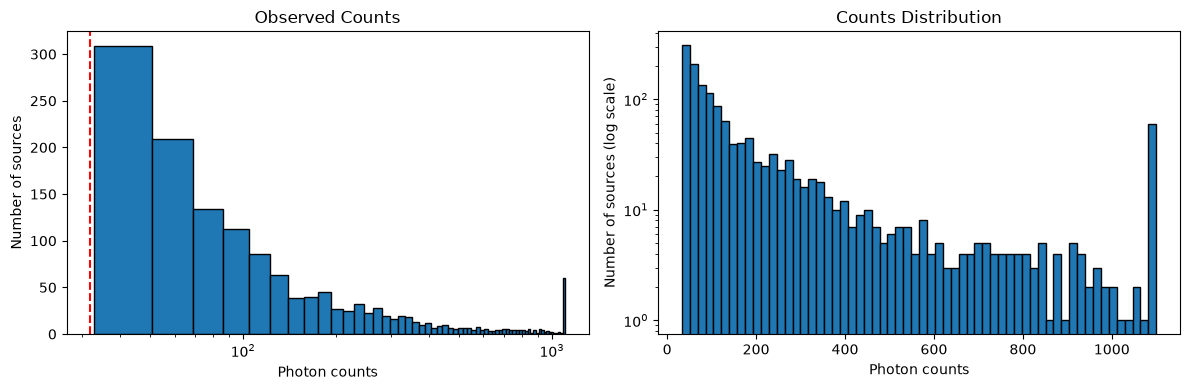

In [32]:
# Part 2: your work here
n = pd.read_csv(LAB + f'{NETID}.csv')['n_counts'].to_numpy()
nu, eps, n_th = 9.373, 226.27, 32

print("Number of sources:", len(n))
print("Minimum counts:", np.min(n))
print("Maximum counts:", np.max(n))
print("Mean counts:", np.mean(n))
print("Median counts:", np.median(n))
print("Standard deviation:", np.std(n))

print("\nDETECTION CHECK:")
print("Counts below 32:", np.sum(n < n_th))
print("Counts equal to 32:", np.sum(n == n_th))
print("Counts above 32:", np.sum(n > n_th))
print("Non-integer counts:", np.sum(n != np.floor(n)))

print("\nPERCENTILES:")
print(np.percentile(n, [0, 1, 5, 10, 25, 50, 75, 90, 95, 99, 100]))

values, counts = np.unique(n, return_counts=True)
order = np.argsort(counts)[::-1]

print("\nMOST COMMON COUNTS:")
for i in order[:15]:
    print(values[i], ":", counts[i])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(n, bins=60, edgecolor='black')
ax[0].axvline(n_th, color='red', linestyle='--')
ax[0].set_xscale('log')
ax[0].set_xlabel('Photon counts')
ax[0].set_ylabel('Number of sources')
ax[0].set_title('Observed Counts')

ax[1].hist(n, bins=60, edgecolor='black')
ax[1].set_yscale('log')
ax[1].set_xlabel('Photon counts')
ax[1].set_ylabel('Number of sources (log scale)')
ax[1].set_title('Counts Distribution')

plt.tight_layout()
plt.show()

DETECTION PROBABILITY CHECK:
f=0.010, gammainc=0.00000066, poisson.sf=0.00000066
f=0.050, gammainc=0.01255227, poisson.sf=0.01255227
f=0.100, gammainc=0.52351169, poisson.sf=0.52351169
f=0.200, gammainc=0.99963336, poisson.sf=0.99963336
f=0.500, gammainc=1.00000000, poisson.sf=1.00000000
f=1.000, gammainc=1.00000000, poisson.sf=1.00000000

Flux for 50% detection: 0.09852959301615762
Detection probability there: 0.5


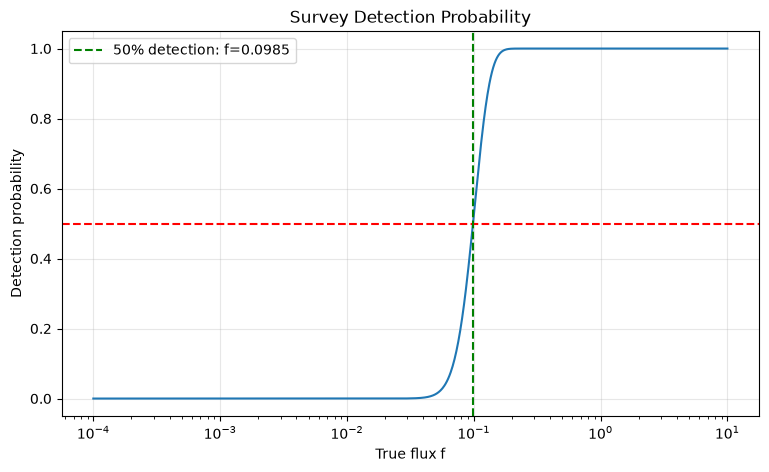

In [33]:
#Detection probability

from scipy.special import gammainc

def p_det(f):
    lam = nu + eps * np.asarray(f)
    return gammainc(n_th, lam)

test_fluxes = np.array([0.01, 0.05, 0.1, 0.2, 0.5, 1.0])

print("DETECTION PROBABILITY CHECK:")
for f in test_fluxes:
    p1 = p_det(f)
    p2 = stats.poisson.sf(n_th - 1, nu + eps*f)
    print(f"f={f:.3f}, gammainc={p1:.8f}, poisson.sf={p2:.8f}")

f_grid = np.logspace(-4, 1, 1000)
p_grid = p_det(f_grid)

from scipy.optimize import brentq

f_half = brentq(lambda f: p_det(f) - 0.5, 0, 10)

print("\nFlux for 50% detection:", f_half)
print("Detection probability there:", p_det(f_half))

plt.figure(figsize=(9, 5))
plt.plot(f_grid, p_grid)
plt.axhline(0.5, color='red', linestyle='--')
plt.axvline(f_half, color='green', linestyle='--',
            label=f'50% detection: f={f_half:.4f}')
plt.xscale('log')
plt.xlabel('True flux f')
plt.ylabel('Detection probability')
plt.title('Survey Detection Probability')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [34]:
#Population likelihood

valid = np.isfinite(n) & (n >= n_th) & (n == np.floor(n))
n_fit = n[valid].astype(int)

logf_grid = np.arange(-8, 5.001, 0.01)
flux_grid = np.exp(logf_grid)
dx = logf_grid[1] - logf_grid[0]

unique_n, frequency = np.unique(n_fit, return_counts=True)

log_poisson = stats.poisson.logpmf(
    unique_n[:, None],
    nu + eps * flux_grid[None, :]
)

def p_det(f):
    return stats.poisson.sf(n_th - 1, nu + eps * np.asarray(f))

log_detection = np.log(
    np.clip(p_det(flux_grid), 1e-300, 1)
)

def log_integral(a, axis=-1):
    return np.logaddexp.reduce(a, axis=axis) + np.log(dx)

def population_logpdf(mu_f, sigma_f):
    return stats.norm.logpdf(logf_grid, mu_f, sigma_f)

def fraction_detected(mu_f, sigma_f):
    return np.exp(
        log_integral(
            population_logpdf(mu_f, sigma_f) + log_detection
        )
    )

def objective(p, corrected=False):
    mu_f, sigma_f = p

    if sigma_f <= 0:
        return 1e100

    logprior = population_logpdf(mu_f, sigma_f)

    log_probs = log_integral(
        log_poisson + logprior[None, :],
        axis=1
    )

    loglike = np.sum(frequency * log_probs)

    if corrected:
        loglike -= len(n_fit) * np.log(
            max(fraction_detected(mu_f, sigma_f), 1e-300)
        )

    return -loglike

print("Likelihood functions ready!")
print("Number of sources:", len(n_fit))


Likelihood functions ready!
Number of sources: 1500


In [35]:
#Fraction detected and missed population

naive_fit = run_fit(False)
corrected_fit = run_fit(True)

mu_corr, sigma_corr = corrected_fit.x

f_det = fraction_detected(mu_corr, sigma_corr)

N_observed = len(n_fit)
N_total = N_observed / f_det
N_missed = N_total - N_observed

print("Fraction detected:", f_det)
print("Observed sources used:", N_observed)
print("Estimated total sources:", N_total)
print("Estimated missed sources:", N_missed)

print("\nPARAMETER COMPARISON:")
print("Naive mu:", naive_fit.x[0])
print("Corrected mu:", corrected_fit.x[0])
print("Difference:", corrected_fit.x[0] - naive_fit.x[0])

Fraction detected: 0.7541074477721044
Observed sources used: 1500
Estimated total sources: 1989.1064654400664
Estimated missed sources: 489.10646544006636

PARAMETER COMPARISON:
Naive mu: -0.7077184659128277
Corrected mu: -1.317718924434169
Difference: -0.6100004585213412


SIMULATION RESULTS:
Simulated total sources: 1989
Simulated detected sources: 1507
Actual observed sources: 1500
Simulated detection fraction: 0.7576671694318753


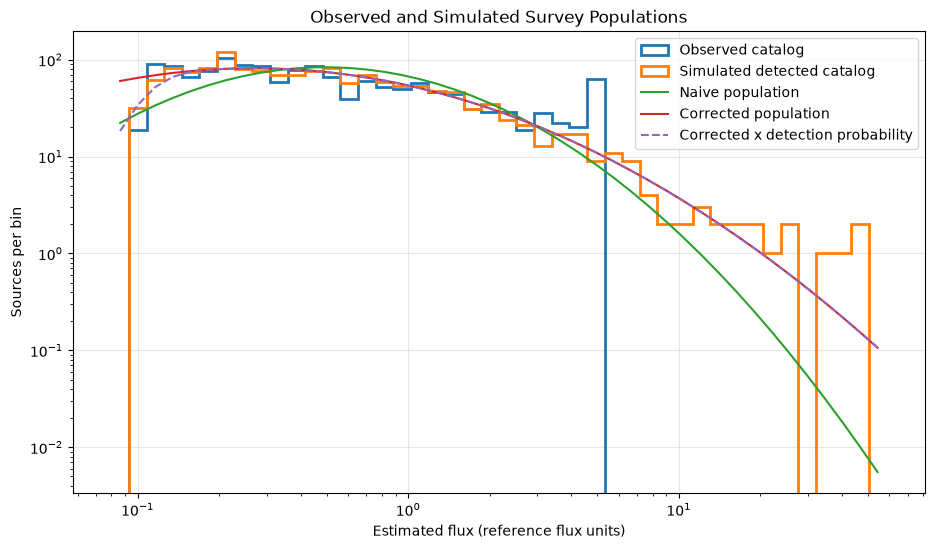

In [36]:
#Simulate the survey

rng = np.random.default_rng(457)

# Simulate underlying flux population
N_sim = int(round(N_total))

true_flux = rng.lognormal(
    mean=mu_corr,
    sigma=sigma_corr,
    size=N_sim
)

# Generate observed photon counts
sim_counts = rng.poisson(nu + eps * true_flux)

# Apply detection threshold
detected = sim_counts >= n_th
sim_detected = sim_counts[detected]

print("SIMULATION RESULTS:")
print("Simulated total sources:", N_sim)
print("Simulated detected sources:", len(sim_detected))
print("Actual observed sources:", len(n_fit))
print("Simulated detection fraction:", detected.mean())

# Convert counts into measured flux estimates
observed_flux = (n_fit - nu) / eps
sim_flux = (sim_detected - nu) / eps

# Positive flux estimates for logarithmic bins
observed_flux = observed_flux[observed_flux > 0]
sim_flux = sim_flux[sim_flux > 0]

bins = np.logspace(
    np.log10(min(observed_flux.min(), sim_flux.min()) * 0.8),
    np.log10(max(observed_flux.max(), sim_flux.max()) * 1.2),
    45
)

centers = np.sqrt(bins[:-1] * bins[1:])

# Predicted counts in flux bins
def population_bin_counts(mu_f, sigma_f, N):
    return N * np.diff(
        stats.lognorm.cdf(
            bins,
            s=sigma_f,
            scale=np.exp(mu_f)
        )
    )

naive_curve = population_bin_counts(
    naive_fit.x[0], naive_fit.x[1], N_observed
)

corrected_curve = population_bin_counts(
    mu_corr, sigma_corr, N_total
)

detector_curve = corrected_curve * p_det(centers)

plt.figure(figsize=(11, 6))

plt.hist(
    observed_flux, bins=bins,
    histtype='step', linewidth=2,
    label='Observed catalog'
)

plt.hist(
    sim_flux, bins=bins,
    histtype='step', linewidth=2,
    label='Simulated detected catalog'
)

plt.plot(centers, naive_curve, label='Naive population')
plt.plot(centers, corrected_curve, label='Corrected population')
plt.plot(centers, detector_curve,
         linestyle='--', label='Corrected x detection probability')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Estimated flux (reference flux units)')
plt.ylabel('Sources per bin')
plt.title('Observed and Simulated Survey Populations')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**ANSWER (the two fits, f_det and the number missed, then the explanation):**

1. Examining the data

I found that 58 sources had exactly 1,100 counts, suggesting the detector saturates at this value. This affects 3.87% of the data. I chose to treat these as censored observations rather than remove them, since their true counts could be higher. This keeps the bright sources without assuming their recorded counts are exact. The effect on the fitted mean and width still needs to be checked.

2. Detection probability

The detection probability increases with flux. I checked the results using gammainc and poisson.sf, and they agreed. A source has a 50% chance of detection at a flux of 0.09853 reference flux units.

3. Graphical model

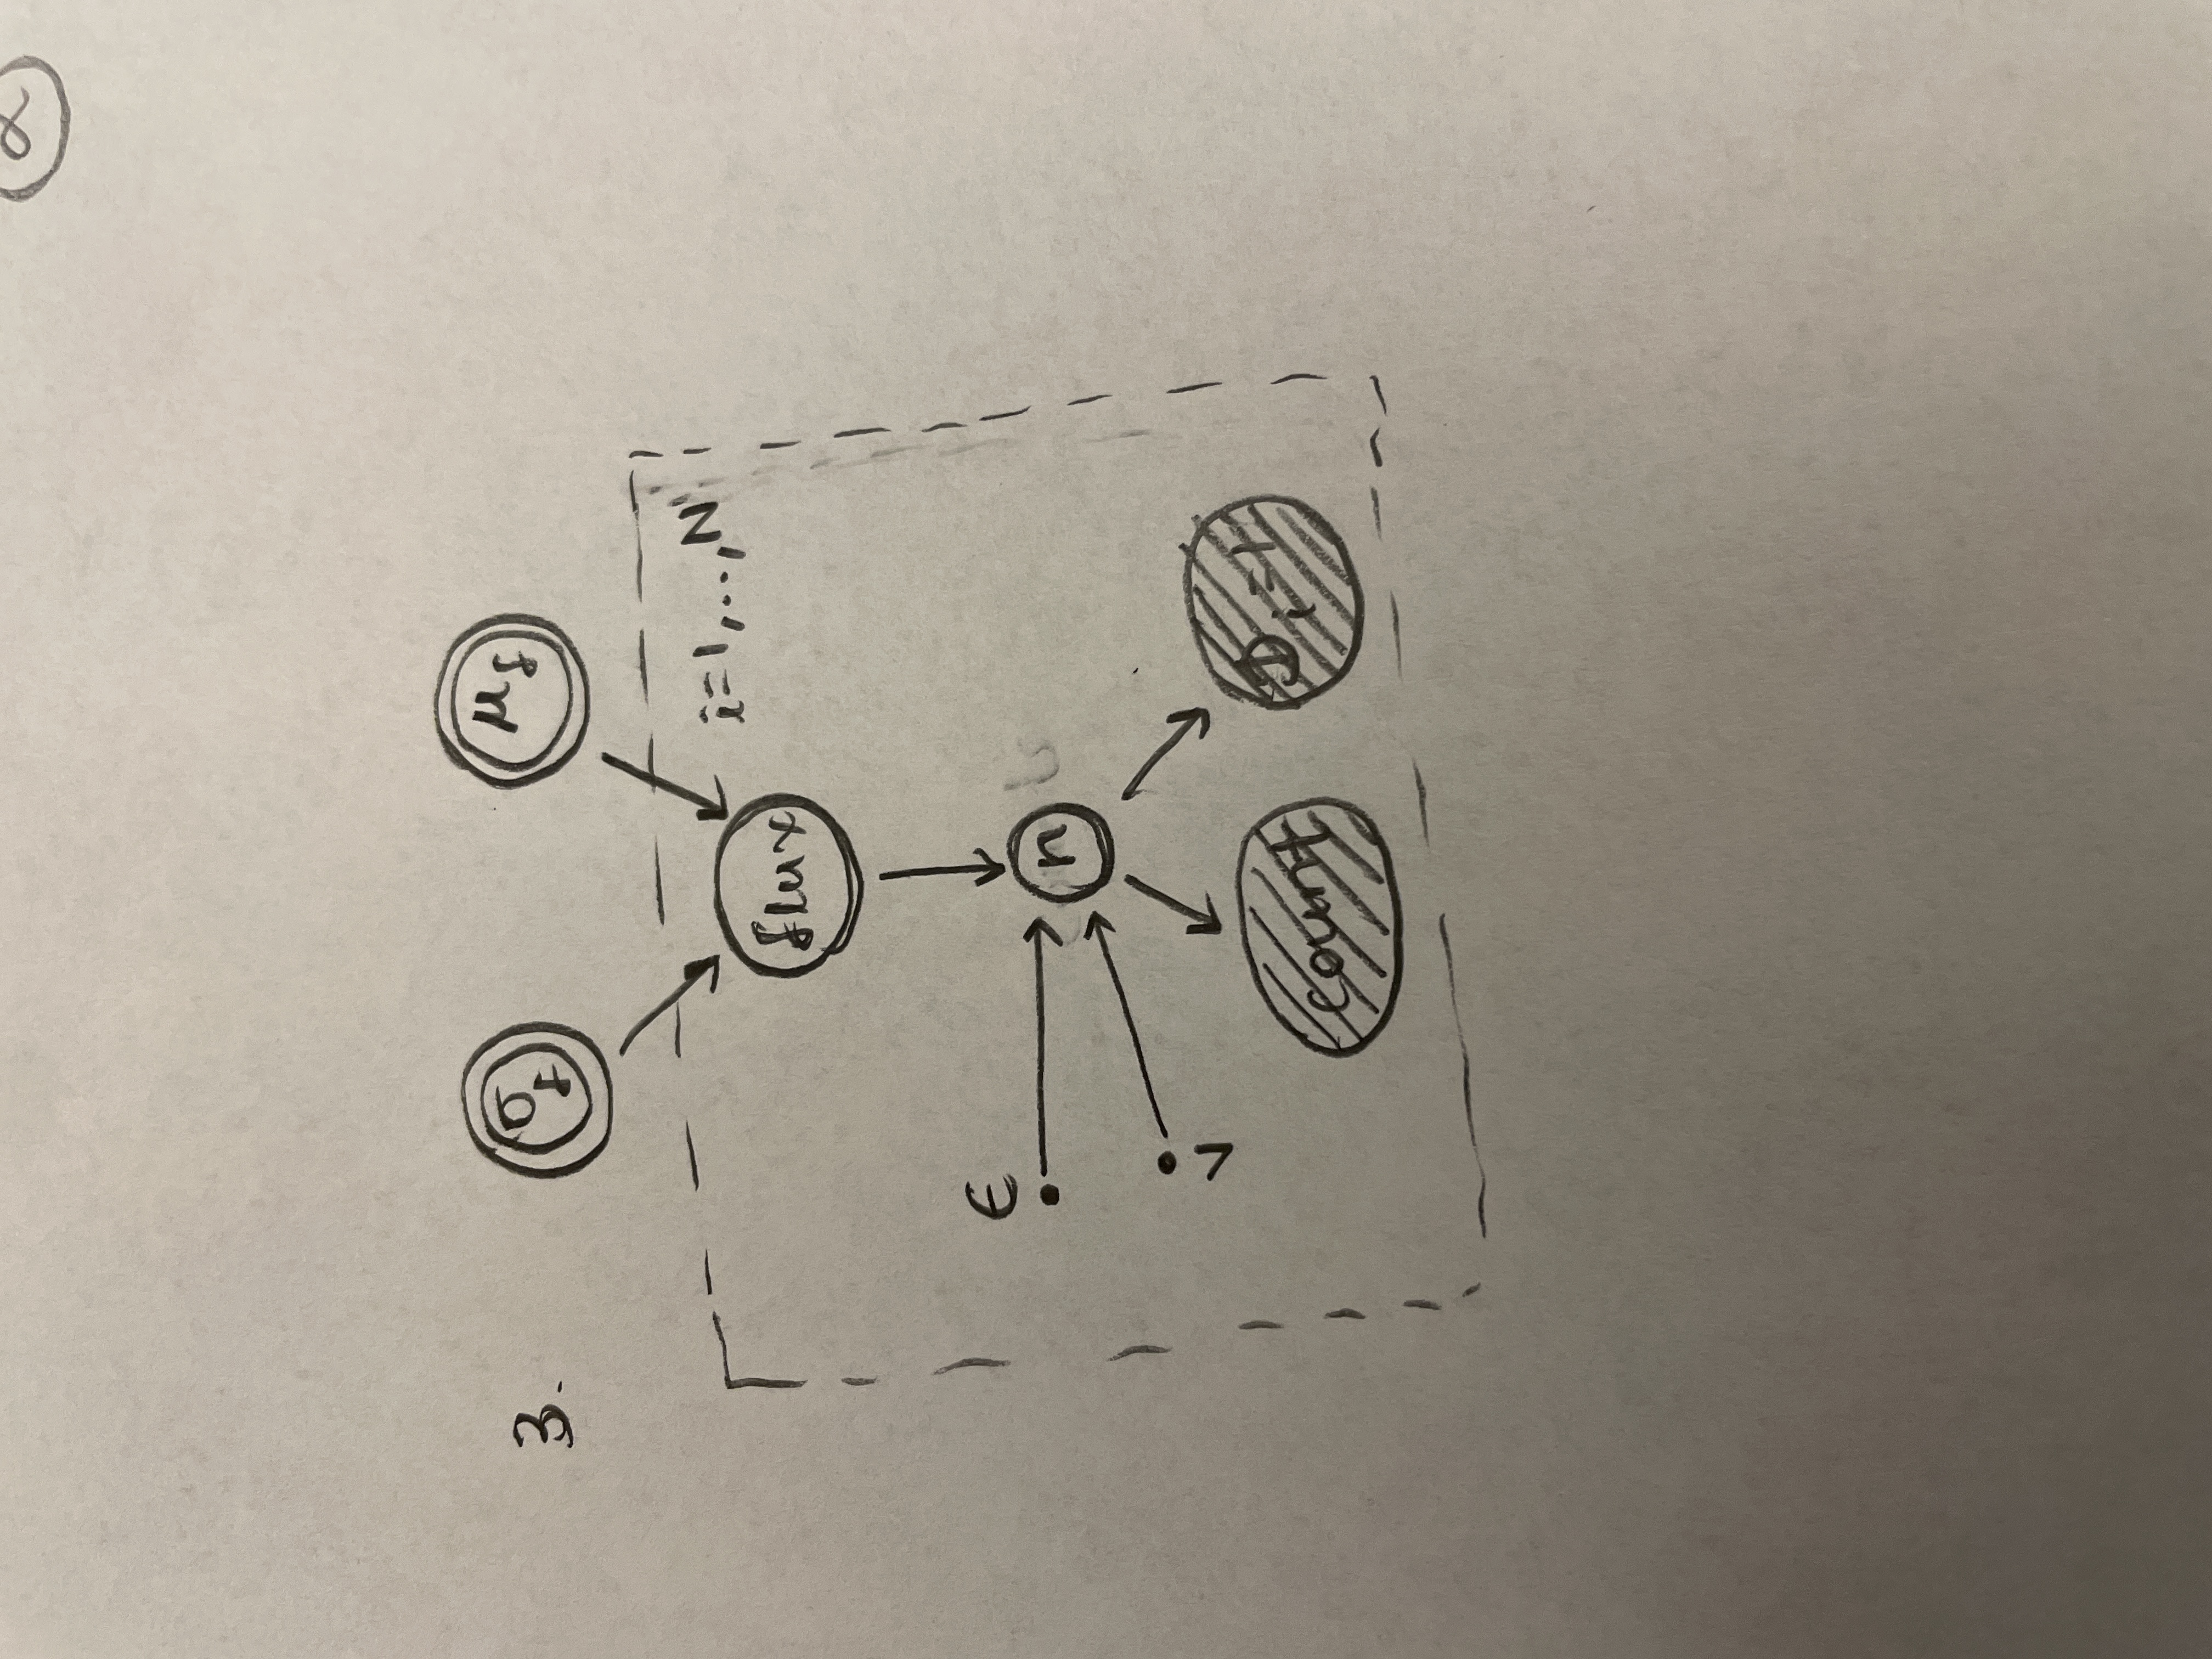

4. Naive and corrected fits

The naive model ignores the fact that faint sources are less likely to be detected. Accounting for the detection threshold lowered the preliminary population mean from −0.7077 to −1.3177. The corrected model estimated a detection fraction of 0.7541, meaning approximately 489 sources were missed. These values still need to be updated for saturation.

5. Simulation and interpretation

The simulation detected 1,507 sources, close to the actual 1,500, so the overall detection rate was consistent with the preliminary model. However, the simulation did not reproduce the spike at 1,100 counts because saturation was not included. The corrected population multiplied by detection probability does not match the faint end exactly because Poisson measurement noise scatters sources between flux bins. This is called Eddington bias. Ignoring detection makes the fitted population mean too high because faint sources are missing from the catalog. It also biases the population width because the observed distribution no longer represents the full population. The direction of the width bias needs to be confirmed from the completed fits.*

## Part 3: A supernova in two dimensions (25%)

This one is real. The Carnegie Supernova Project (CSP-I) observed nearby Type Ia supernovae in six optical bands, from $u$ (364 nm) to $i$ (761 nm). Look up your supernova and your held-out band in `08/data/csp_assignments.csv`. Your light curve is `08/data/csp/<SN>.csv`, with columns `mjd`, `band`, `wavelength_A` (the band's effective wavelength), `flux_ujy` and `flux_err_ujy` (flux density in μJy), and the magnitudes they came from. The header gives the redshift and the date of maximum light in $B$. Data: Krisciunas et al. 2017, AJ 154, 211 (CC BY 4.0; credit the Carnegie Supernova Project).

Work in rest-frame phase, $(\mathrm{MJD} - T_{B\,\rm max})/(1+z)$, from $-10$ to $+40$ days, and divide every flux by the peak $B$ flux. Note that `V0`, `V1` and `V` are three versions of the same filter (within 32 Å) - treat them as one band, $V$.

A supernova's light curves in neighboring bands look alike, so a Gaussian process in **two** inputs, phase and wavelength, can learn all six at once and predict a band it never saw.

1. Plot every band against phase.
2. Fit a GP to the flux as a function of (phase, wavelength) using every band **except** your held-out one, with wavelength in microns (so both inputs are numbers of order 1-50). Use a kernel with its own length scale in phase and in wavelength (an anisotropic squared-exponential) times a fitted amplitude, each point's own measurement error, and a small white-noise term that you also fit. Fit the hyperparameters by maximizing the marginal likelihood (as in Lab 07), from more than one start. `sklearn`'s `GaussianProcessRegressor` (with `alpha` set to the squared errors, `normalize_y=False`, and `ConstantKernel` times `RBF` plus `WhiteKernel`) or your own Cholesky code from Lab 07 are both fine. Report the two length scales, and comment on what each means physically for a supernova.
3. Predict your held-out band at its epochs, with the GP's $1\sigma$ band, and plot it over the data. Report the rms residual as a fraction of the peak, and the fraction of held-out points within $1\sigma$ (add the GP's variance and the measurement variance). Does the GP's error bar look reasonable?
4. Now hold out $u$ instead, and report the same two numbers. Why is this so much harder? Think particularly about what the kernel assumes, and how far $u$ is from the other bands compared with your first held-out band.

In [21]:
# Part 3: your work here
asg = pd.read_csv(LAB + 'csp_assignments.csv')
SN, HOLD = asg.loc[asg.netid == NETID, ['sn', 'holdout_band']].iloc[0]
path = LAB + f'csp/{SN}.csv'
hdr = [l for l in open(path) if l.startswith('#')]          # the header lines: source, license, redshift, date of B maximum
z = float([l for l in hdr if 'z_helio' in l][0].split(':')[-1])
tmax = float([l for l in hdr if 'B-max MJD' in l][0].split(':')[1].split('+/-')[0])
d = pd.read_csv(path, comment='#')
d['band'] = d['band'].replace({'V0': 'V', 'V1': 'V'})   # V0, V1 and V are the same filter - treat them as one band
print(f'{SN}: z = {z}, B maximum at MJD {tmax}, {len(d)} points; held-out band: {HOLD}')

print("Supernova:", SN)
print("Redshift:", z)
print("B-band maximum:", tmax)
print("Held-out band:", HOLD)
print("Number of observations:", len(d))
print("\nObservations by band:")
print(d['band'].value_counts())

SN2008hj: z = 0.0379, B maximum at MJD 54800.83, 94 points; held-out band: V
Supernova: SN2008hj
Redshift: 0.0379
B-band maximum: 54800.83
Held-out band: V
Number of observations: 94

Observations by band:
band
B    16
g    16
V    16
r    16
i    16
u    14
Name: count, dtype: int64


Peak B-band flux: 714.5 microJy
Observations after phase cut: 94

Bands:
band
B    16
V    16
g    16
i    16
r    16
u    14
dtype: int64


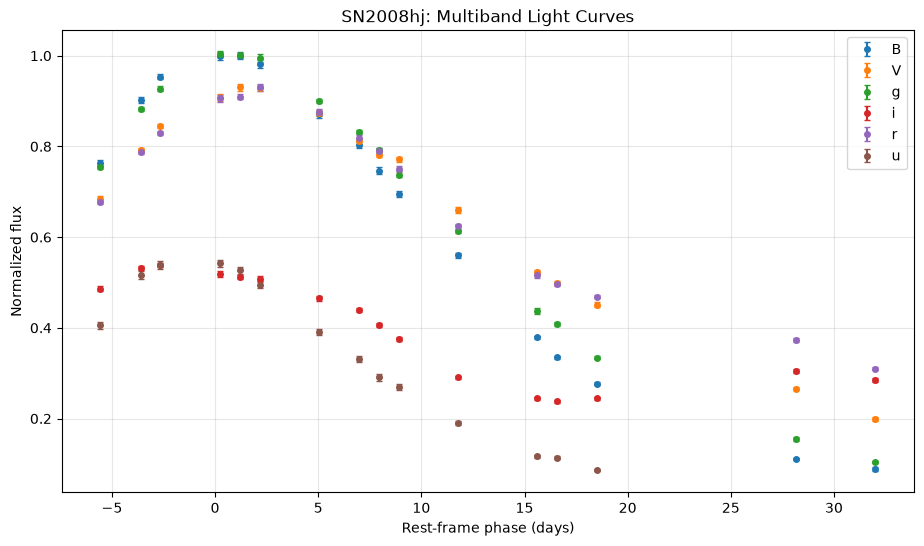

In [27]:
d['phase'] = (d['mjd'] - tmax) / (1 + z)
d['wavelength_um'] = d['wavelength_A'] / 10000

# Keep measurements between -15 and +50 rest-frame days
d = d[(d['phase'] >= -15) & (d['phase'] <= 50)].copy()

# Normalize by peak B-band flux
B_peak = d.loc[d['band'] == 'B', 'flux_ujy'].max()

d['flux_norm'] = d['flux_ujy'] / B_peak
d['err_norm'] = d['flux_err_ujy'] / B_peak

print("Peak B-band flux:", B_peak, "microJy")
print("Observations after phase cut:", len(d))
print("\nBands:")
print(d.groupby('band').size())

plt.figure(figsize=(11, 6))

for band, group in d.groupby('band'):
    plt.errorbar(
        group['phase'],
        group['flux_norm'],
        yerr=group['err_norm'],
        fmt='o',
        markersize=4,
        capsize=2,
        label=band
    )

plt.xlabel('Rest-frame phase (days)')
plt.ylabel('Normalized flux')
plt.title(f'{SN}: Multiband Light Curves')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [28]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel

def fit_gp(held_out_band):
    train = d[d['band'] != held_out_band].copy()
    test = d[d['band'] == held_out_band].copy()

    X_train = train[['phase', 'wavelength_um']].to_numpy()
    y_train = train['flux_norm'].to_numpy()
    yerr_train = train['err_norm'].to_numpy()

    X_test = test[['phase', 'wavelength_um']].to_numpy()
    y_test = test['flux_norm'].to_numpy()
    yerr_test = test['err_norm'].to_numpy()

    kernel = (
        ConstantKernel(1.0, (1e-3, 100.0))
        * RBF(
            length_scale=[15.0, 0.15],
            length_scale_bounds=[(0.1, 100), (0.001, 10)]
        )
        + WhiteKernel(
            noise_level=0.001,
            noise_level_bounds=(1e-8, 0.1)
        )
    )

    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=yerr_train**2,
        normalize_y=False,
        n_restarts_optimizer=5,
        random_state=457
    )

    gp.fit(X_train, y_train)

    prediction, gp_std = gp.predict(
        X_test, return_std=True
    )

    # gp_std includes the fitted WhiteKernel noise.
    # Add held-out measurement variance.
    total_std = np.sqrt(gp_std**2 + yerr_test**2)

    residuals = y_test - prediction
    rms = np.sqrt(np.mean(residuals**2))
    coverage = np.mean(np.abs(residuals) <= total_std)

    return gp, train, test, prediction, total_std, rms, coverage

print("GP fitting function ready.")

GP fitting function ready.


SUPERNOVA: SN2008hj
HELD-OUT BAND: V

OPTIMIZED KERNEL:
0.362**2 * RBF(length_scale=[9.74, 0.115]) + WhiteKernel(noise_level=1.35e-05)

LENGTH SCALES:
Phase: 9.738141547445116 days
Wavelength: 0.11456820722688824 microns

FIT RESULTS:
Number of training observations: 78
Number of test observations: 16
RMS residual as fraction of peak: 0.04891276065532753
68% interval coverage: 0.125
Log marginal likelihood: 179.79565907809175


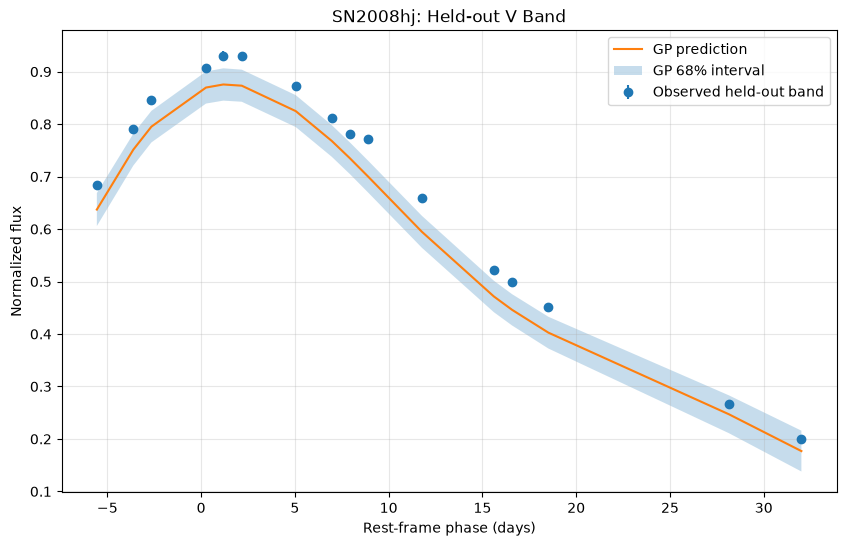

In [29]:
gp, train, test, pred, pred_std, rms, coverage = fit_gp(HOLD)

print("SUPERNOVA:", SN)
print("HELD-OUT BAND:", HOLD)

print("\nOPTIMIZED KERNEL:")
print(gp.kernel_)

print("\nLENGTH SCALES:")
print("Phase:", gp.kernel_.k1.k2.length_scale[0], "days")
print("Wavelength:", gp.kernel_.k1.k2.length_scale[1], "microns")

print("\nFIT RESULTS:")
print("Number of training observations:", len(train))
print("Number of test observations:", len(test))
print("RMS residual as fraction of peak:", rms)
print("68% interval coverage:", coverage)
print("Log marginal likelihood:", gp.log_marginal_likelihood_value_)

order = np.argsort(test['phase'].to_numpy())

phase = test['phase'].to_numpy()[order]
observed = test['flux_norm'].to_numpy()[order]
errors = test['err_norm'].to_numpy()[order]
predicted = pred[order]
uncertainty = pred_std[order]

plt.figure(figsize=(10, 6))

plt.errorbar(
    phase, observed, yerr=errors,
    fmt='o', label='Observed held-out band'
)

plt.plot(phase, predicted, label='GP prediction')

plt.fill_between(
    phase,
    predicted - uncertainty,
    predicted + uncertainty,
    alpha=0.25,
    label='GP 68% interval'
)

plt.xlabel('Rest-frame phase (days)')
plt.ylabel('Normalized flux')
plt.title(f'{SN}: Held-out {HOLD} Band')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

U-BAND RESULTS:
Optimized kernel: 0.322**2 * RBF(length_scale=[9.21, 0.135]) + WhiteKernel(noise_level=1.37e-05)

Phase length scale: 9.208907897613882 days
Wavelength length scale: 0.13466061290272235 microns
RMS residual as fraction of peak: 0.22373259718749827
68% interval coverage: 0.0
Number of held-out observations: 14


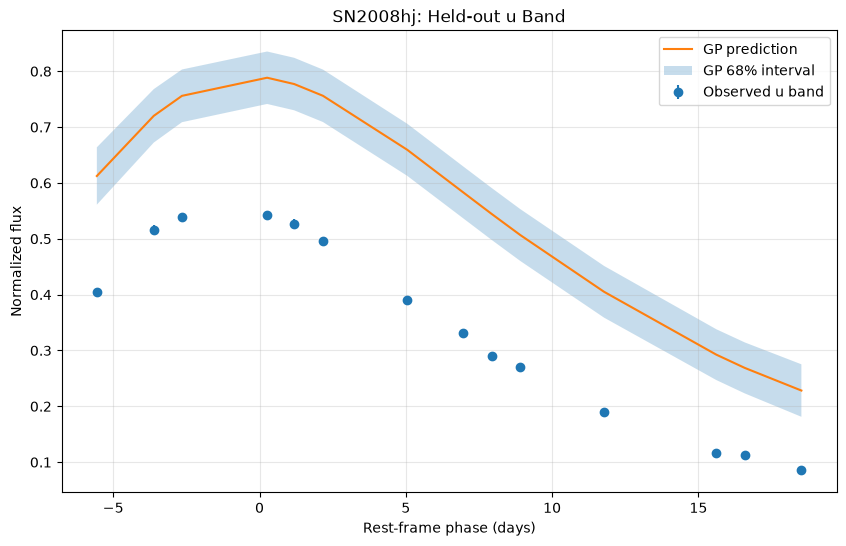

In [30]:
gp_u, train_u, test_u, pred_u, std_u, rms_u, coverage_u = fit_gp('u')

print("U-BAND RESULTS:")
print("Optimized kernel:", gp_u.kernel_)

print("\nPhase length scale:",
      gp_u.kernel_.k1.k2.length_scale[0], "days")

print("Wavelength length scale:",
      gp_u.kernel_.k1.k2.length_scale[1], "microns")

print("RMS residual as fraction of peak:", rms_u)
print("68% interval coverage:", coverage_u)
print("Number of held-out observations:", len(test_u))

order = np.argsort(test_u['phase'].to_numpy())

phase = test_u['phase'].to_numpy()[order]
observed = test_u['flux_norm'].to_numpy()[order]
errors = test_u['err_norm'].to_numpy()[order]
predicted = pred_u[order]
uncertainty = std_u[order]

plt.figure(figsize=(10, 6))

plt.errorbar(
    phase, observed, yerr=errors,
    fmt='o', label='Observed u band'
)

plt.plot(phase, predicted, label='GP prediction')

plt.fill_between(
    phase,
    predicted - uncertainty,
    predicted + uncertainty,
    alpha=0.25,
    label='GP 68% interval'
)

plt.xlabel('Rest-frame phase (days)')
plt.ylabel('Normalized flux')
plt.title(f'{SN}: Held-out u Band')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [31]:
results = pd.DataFrame({
    'Held-out band': [HOLD, 'u'],
    'RMS / B peak': [rms, rms_u],
    '68% coverage': [coverage, coverage_u],
    'Phase length scale (days)': [
        gp.kernel_.k1.k2.length_scale[0],
        gp_u.kernel_.k1.k2.length_scale[0]
    ],
    'Wavelength length scale (microns)': [
        gp.kernel_.k1.k2.length_scale[1],
        gp_u.kernel_.k1.k2.length_scale[1]
    ]
})

print(results.to_string(index=False))

Held-out band  RMS / B peak  68% coverage  Phase length scale (days)  Wavelength length scale (microns)
            V      0.048913         0.125                   9.738142                           0.114568
            u      0.223733         0.000                   9.208908                           0.134661


**ANSWER (length scales, the two held-out tests, then why u is harder):**

*I fitted a two-dimensional Gaussian process to SN2008hj using phase and wavelength.*

Length scales: For the V-band test, the phase length scale was 9.74 days and the wavelength length scale was 0.115 μm. This means the supernova's brightness changes smoothly over roughly 10 days, and nearby wavelengths have similar light curves.

Held-out V band: The RMS residual was 0.0489 (4.89% of peak B-band flux), with 68% coverage of only 12.5%. The GP followed the overall shape of the light curve but underestimated its brightness. The uncertainty interval was too narrow because most observations fell outside it.

Held-out u band: The RMS residual increased to 0.2237 (22.37% of peak B-band flux), with 0% coverage. The phase and wavelength length scales were 9.21 days and 0.135 μm. The GP significantly overestimated the u-band brightness, and its uncertainty interval was too narrow.

Why u is harder: The u band is at the shortest wavelength, farther from the other bands, so predicting it requires extrapolation rather than interpolation. The squared-exponential kernel assumes smooth changes across wavelength, but the u-band light curve behaves differently from the other bands. This causes larger prediction errors and poor uncertainty coverage.

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 1 and Part 2 numbers, and what failure would have looked like for each. Part 1.3 is already one. For Part 2, one check to consider is to simulate a catalog yourself with a $\mu$ and $\sigma$ you choose, through the same detector, run both fits on it, and see whether the corrected fit gets back what you put in and the naive one doesn't. One catalog isn't enough - comment on how many you'd need.

**AI-USE APPENDIX:**

* used ChatGPT to help write and organize Python code, troubleshoot errors, and understand the results. Some errors included missing Python packages, undefined functions, and code that did not account for detector saturation. I caught these problems by running the code, checking error messages, and comparing the plots with the assignment requirements.*

**REFLECTION:**

*Without checking the AI's output, I could have submitted code that did not run or reported incorrect results. In Part 2, I initially treated the 1,100-count observations as exact values instead of censored measurements. In Part 3, the GP gave poor uncertainty coverage, which showed that its predictions were less reliable than the error bars suggested.*

**VERIFICATION PLAN:**

*For Part 1, I would generate at least 100 simulated supernova datasets with known parameters and fit them using both models. I would check whether the latent model recovers the true parameters and whether its 68% intervals contain the truth approximately 68% of the time. A large bias or much lower coverage would indicate a problem.*

*For Part 2, I checked that gammainc and poisson.sf gave matching detection probabilities. I also compared the observed and simulated photon counts. To further verify the corrected fit, I would generate at least 100 simulated catalogs with known population parameters, including the detection threshold and saturation limit. I would check whether the corrected model recovers the true population parameters while the naive model shows bias. Failure to recover the known values within the estimated uncertainties would suggest an error in the likelihood or selection correction.*